# Lab 1.4 - Generate Images with a Diffusion Pipeline (Solution)
**Day 1 - Session 4**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kpassoubady/gen-ai-companion-intuite/blob/main/day1/lab1_4_diffusion/solution/lab1_4_diffusion.ipynb)

**Goal:** Run a pre-trained diffusion model (inference only) and see how it
turns random noise into images by denoising, one step at a time.

The core lab uses a small unconditional model that generates 32x32 images in
well under a second on a Colab CPU runtime. The text-to-image stretch goal
runs best on a free T4 runtime.

In [1]:
# Scoped install for this lab (safe to re-run; preinstalled on Colab).
%pip install -q diffusers transformers accelerate torch matplotlib

In [2]:
import matplotlib.pyplot as plt
import torch
from diffusers import DDIMScheduler, DDPMPipeline

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


Using device: cpu


## 1. Load a pre-trained diffusion pipeline
`google/ddpm-cifar10-32` is a small model trained to generate 32x32 images.
We swap in the DDIM scheduler so we can generate with far fewer steps.

In [3]:
pipe = DDPMPipeline.from_pretrained("google/ddpm-cifar10-32").to(device)
pipe.scheduler = DDIMScheduler.from_config(pipe.scheduler.config)
print("Pipeline loaded.")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


model_index.json:   0%|          | 0.00/180 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/2 [00:00<?, ?it/s]

Pipeline loaded.


## 2. Generate an image
Generation starts from random noise and denoises it step by step. A fixed seed
makes the result repeatable.

  0%|          | 0/25 [00:00<?, ?it/s]

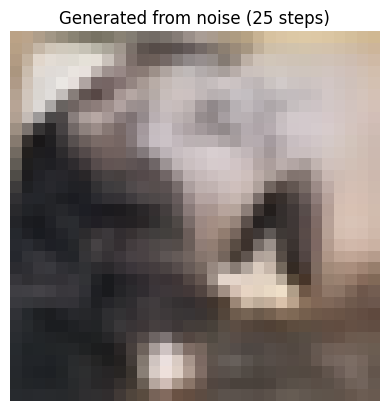

In [4]:
generator = torch.Generator(device=device).manual_seed(42)
image = pipe(num_inference_steps=25, generator=generator).images[0]

plt.imshow(image)
plt.axis("off")
plt.title("Generated from noise (25 steps)")
plt.show()

## 3. More steps, more refinement
Compare the same seed at different step counts. Fewer steps are faster but
rougher; more steps refine the image.

  0%|          | 0/2 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

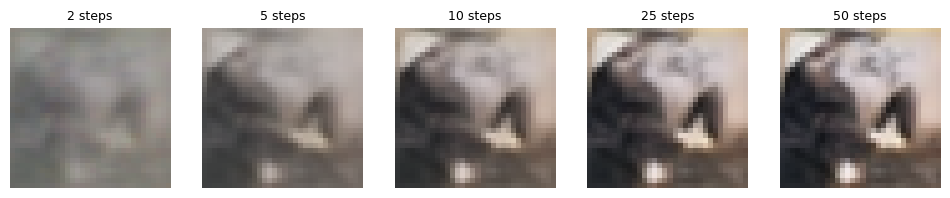

In [5]:
step_counts = [2, 5, 10, 25, 50]
fig, axes = plt.subplots(1, len(step_counts), figsize=(12, 3))
for ax, steps in zip(axes, step_counts):
    g = torch.Generator(device=device).manual_seed(42)
    img = pipe(num_inference_steps=steps, generator=g).images[0]
    ax.imshow(img)
    ax.set_title(f"{steps} steps", fontsize=9)
    ax.axis("off")
plt.show()

## 4. Reproducibility with seeds
The same seed gives the same image; a different seed gives a different one.

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

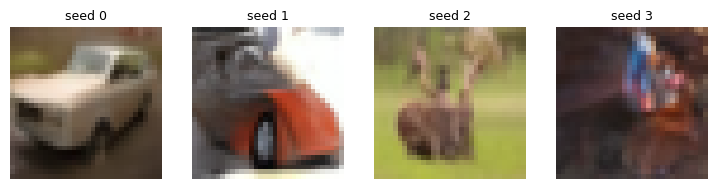

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(9, 2.5))
for ax, seed in zip(axes, [0, 1, 2, 3]):
    g = torch.Generator(device=device).manual_seed(seed)
    img = pipe(num_inference_steps=25, generator=g).images[0]
    ax.imshow(img)
    ax.set_title(f"seed {seed}", fontsize=9)
    ax.axis("off")
plt.show()

## Stretch goals
1. **Text-to-image.** Run a Stable Diffusion pipeline and generate an image
   from your own prompt. This downloads a larger model and runs much faster on
   a T4 runtime than on CPU. `sd-turbo` needs only one step.
2. **Guidance sweep.** With the text-to-image pipeline, vary `guidance_scale`
   and watch how closely the image follows the prompt.

In [ ]:
# Stretch 1: text-to-image with Stable Diffusion Turbo (T4 recommended).
# Uncomment to run. On CPU this is slow; on a T4 it takes a second or two.
#
# from diffusers import AutoPipelineForText2Image
#
# sd = AutoPipelineForText2Image.from_pretrained(
#     "stabilityai/sd-turbo",
#     torch_dtype=torch.float16 if device == "cuda" else torch.float32,
# ).to(device)
# prompt = "a cozy cabin in a snowy forest, digital art"
# result = sd(prompt=prompt, num_inference_steps=1, guidance_scale=0.0).images[0]
# plt.imshow(result)
# plt.axis("off")
# plt.title(prompt, fontsize=9)
# plt.show()

### Expected output
- The first image is a small, colorful 32x32 picture generated from noise.
- At 2 steps the image is rough; by 25-50 steps it is smoother and more
  coherent.
- The same seed always reproduces the same image; different seeds differ.
- The text-to-image stretch produces an image that matches your prompt.